# Лабораторная работа 6 (В26)
## Введение
**Название:** кластеризация

**Цель:** научиться производить кластерный анализ данных с использованием метода К-средних.

**Описание показателей:**
- User_ID - уникальный идентификатор пользователя
- Age – возраст пользователя
- Gender – Пол Мужской/Женский/Другой
- Sleep_Duration – количество часов сна в сутки
- Stress_Level – уровень стресса (от 1 до 10)
- Diet_Type – тип диеты (вегетарианец, невегетарианец, веган)
- Daily_Screen_Time – часы, проведенные за экранами ежедневно
- Exercise_Frequency – частота упражнений (Низкий, Средний, Высокий)
- Caffeine_Intake – потребление кофеина (мг в день)
- Reaction_Time – время реакции в миллисекундах (мс)
- Memory_Test_Score – оценка памяти по 100-балльной шкале
- Cognitive_Score – общая оценка когнитивных способностей, сгенерированная
искусственным интеллектом
- AI_Predicted_Score – прогнозирование когнитивных показателей с помощью
модели машинного обучения

## 1. Подготовительный этап
## 1.1 Импортируем библиотеки и загружаем данные

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('human_cognitive_performance.csv')
df.head()

,User_ID,Age,Gender,Sleep_Duration,Stress_Level,Diet_Type,Daily_Screen_Time,Exercise_Frequency,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,AI_Predicted_Score
0,U1,57,Female,6.5,3,Non-Vegetarian,6.5,Medium,41,583.33,65,36.71,39.77
1,U2,39,Female,7.6,9,Non-Vegetarian,10.8,High,214,368.24,58,54.35,57.68
2,U3,26,Male,8.2,6,Vegetarian,5.7,Low,429,445.21,49,32.57,29.54
3,U4,32,Male,7.8,9,Vegetarian,8.3,Low,464,286.33,94,70.15,74.59
4,U5,50,Male,9.7,2,Non-Vegetarian,11.3,Medium,365,237.65,62,87.54,91.78


### 1.2 Получим информацию о датасете

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   User_ID             80000 non-null  object 
 1   Age                 80000 non-null  int64  
 2   Gender              80000 non-null  object 
 3   Sleep_Duration      80000 non-null  float64
 4   Stress_Level        80000 non-null  int64  
 5   Diet_Type           80000 non-null  object 
 6   Daily_Screen_Time   80000 non-null  float64
 7   Exercise_Frequency  80000 non-null  object 
 8   Caffeine_Intake     80000 non-null  int64  
 9   Reaction_Time       80000 non-null  float64
 10  Memory_Test_Score   80000 non-null  int64  
 11  Cognitive_Score     80000 non-null  float64
 12  AI_Predicted_Score  80000 non-null  float64
dtypes: float64(5), int64(4), object(4)
memory usage: 7.9+ MB


## 2. Преобразования датасета
### 2.1 Проверим данные на наличие пропущенных значений

In [3]:
print(df.isnull().sum())

User_ID               0
Age                   0
Gender                0
Sleep_Duration        0
Stress_Level          0
Diet_Type             0
Daily_Screen_Time     0
Exercise_Frequency    0
Caffeine_Intake       0
Reaction_Time         0
Memory_Test_Score     0
Cognitive_Score       0
AI_Predicted_Score    0
dtype: int64


Пропущенных значений нет, прекрасно
### 2.2 Исключаем невлияющие категориальные признаки

In [4]:
y = df['User_ID']
df.drop('User_ID', axis=1, inplace=True)
df.head()

,Age,Gender,Sleep_Duration,Stress_Level,Diet_Type,Daily_Screen_Time,Exercise_Frequency,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,AI_Predicted_Score
0,57,Female,6.5,3,Non-Vegetarian,6.5,Medium,41,583.33,65,36.71,39.77
1,39,Female,7.6,9,Non-Vegetarian,10.8,High,214,368.24,58,54.35,57.68
2,26,Male,8.2,6,Vegetarian,5.7,Low,429,445.21,49,32.57,29.54
3,32,Male,7.8,9,Vegetarian,8.3,Low,464,286.33,94,70.15,74.59
4,50,Male,9.7,2,Non-Vegetarian,11.3,Medium,365,237.65,62,87.54,91.78


### 2.3 Кодирование категориальных переменных
#### 2.3.1 OneHotEncoder

In [5]:
print(df.Gender.unique())
print(df.Diet_Type.unique())
print(df.Exercise_Frequency.unique())

['Female' 'Male' 'Other']
['Non-Vegetarian' 'Vegetarian' 'Vegan']
['Medium' 'High' 'Low']


Как можно заметить, каждая категориальная переменная имеет три варианта значения. Первоначально возникает желаение применить OneHotEncoder с удалением одного столбца (для определения какой столбец удалить можно построить график и выберать значение, с наименьшим числом выпадения). Пример такого представлен в следующих 4х ячейках markdown (код оставлен, чтобы при желании можно было посмотреть на работу такого развития событий и увидеть, к чему он приводит).

gender_counts = df.Gender.value_counts()
sns.barplot(x = gender_counts.index, y = gender_counts.values)
plt.title('Распределение по категориям')
plt.xlabel('КОличество в категории')
plt.ylabel('Категории')

diet_counts = df.Diet_Type.value_counts()
sns.barplot(x = diet_counts.index, y = diet_counts.values)
plt.title('Распределение по категориям')
plt.xlabel('КОличество в категории')
plt.ylabel('Категории')

exercise_counts = df.Exercise_Frequency.value_counts()
sns.barplot(x = exercise_counts.index, y = exercise_counts.values)
plt.title('Распределение по категориям')
plt.xlabel('Количество в категории')
plt.ylabel('Категории')

from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_array = encoder.fit_transform(df[['Gender', 'Diet_Type', 'Exercise_Frequency']])
dfEnc = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(['Gender', 'Diet_Type', 'Exercise_Frequency']))
df = df.join(dfEnc)
df.drop(['Gender', 'Diet_Type', 'Exercise_Frequency', 'Gender_Other', 
         'Diet_Type_Vegan', 'Exercise_Frequency_High'], axis=1, inplace=True)
df.head(15)


#### 2.3.2 LabelEncoder
Однако после проб оказалось, что данный способ не подходит для текущего датасета. Потому применим LabelEncoder

In [6]:
from sklearn.preprocessing import LabelEncoder
labelEncoder = LabelEncoder()
dfLEnc = df.copy()
#dfLEnc['Gender'] = dfLEnc['Gender'].astype('object')
dfLEnc.loc[:,'Gender'] = labelEncoder.fit_transform(dfLEnc.loc[:,'Gender'])
#dfLEnc['Gender'] = dfLEnc['Diet_Type'].astype('object')
dfLEnc.loc[:,'Diet_Type'] = labelEncoder.fit_transform(dfLEnc.loc[:,'Diet_Type'])
#dfLEnc['Gender'] = dfLEnc['Exercise_Frequency'].astype('object')
dfLEnc.loc[:,'Exercise_Frequency'] = labelEncoder.fit_transform(dfLEnc.loc[:,'Exercise_Frequency'])
dfLEnc

,Age,Gender,Sleep_Duration,Stress_Level,Diet_Type,Daily_Screen_Time,Exercise_Frequency,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,AI_Predicted_Score
0,57,0,6.5,3,0,6.5,2,41,583.33,65,36.71,39.77
1,39,0,7.6,9,0,10.8,0,214,368.24,58,54.35,57.68
2,26,1,8.2,6,2,5.7,1,429,445.21,49,32.57,29.54
3,32,1,7.8,9,2,8.3,1,464,286.33,94,70.15,74.59
4,50,1,9.7,2,0,11.3,2,365,237.65,62,87.54,91.78
...,...,...,...,...,...,...,...,...,...,...,...,...
79995,55,1,7.8,9,0,9.4,1,157,312.34,55,50.80,46.49
79996,35,0,9.8,6,2,6.5,2,130,290.17,86,94.89,92.41
79997,32,0,7.3,10,0,7.5,1,462,249.57,72,63.51,67.35
79998,34,1,8.7,8,2,7.2,2,96,319.48,82,81.43,77.95


### 2.4 Применям операцию нормализации для численной устойчивости

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [8]:
X = scaler.fit_transform(dfLEnc)
print (X[:4,:])

[[ 1.52658897e+00 -9.79114977e-01 -2.91354617e-01 -8.70335151e-01
  -7.78590218e-01 -1.46705837e-03  1.06928704e+00 -1.43895564e+00
   1.58930947e+00 -2.59936825e-01 -9.30785107e-01 -7.93762587e-01]
 [ 3.92069761e-02 -9.79114977e-01  3.42861625e-01  1.22369381e+00
  -7.78590218e-01  1.35626250e+00 -1.59876121e+00 -2.42064131e-01
  -2.75062509e-01 -6.64431312e-01 -1.65770327e-01 -1.90902977e-02]
 [-1.03501335e+00  7.66576981e-01  6.88797757e-01  1.76679331e-01
   1.44001058e+00 -2.54067907e-01 -2.64737088e-01  1.24540220e+00
   3.92103382e-01 -1.18449565e+00 -1.11032939e+00 -1.23624709e+00]
 [-5.39219353e-01  7.66576981e-01  4.58173669e-01  1.22369381e+00
   1.44001058e+00  5.66884851e-01 -2.64737088e-01  1.48754788e+00
  -9.85047674e-01  1.41582605e+00  5.19446993e-01  7.12328374e-01]]


Выше привели данные к единому масштабу.
## 3. Кластеризация
### 3.1 Определяем оптимальное количество кластеров с помощью метода локтя

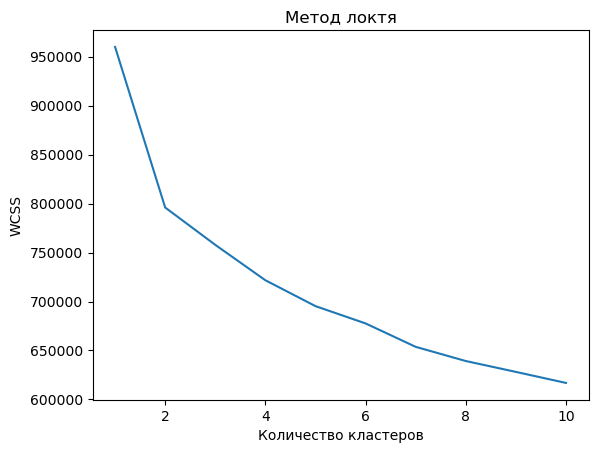

In [9]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('Метод локтя')
plt.xlabel('Количество кластеров')
plt.ylabel('WCSS')
plt.show()

### 3.2 Обучаем модель кластеризации

In [10]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


### 3.3 Предсказываем кластеры

In [11]:
clusters = kmeans.predict(X)
df['cluster'] = clusters
df.head()

,Age,Gender,Sleep_Duration,Stress_Level,Diet_Type,Daily_Screen_Time,Exercise_Frequency,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,AI_Predicted_Score,cluster
0,57,Female,6.5,3,Non-Vegetarian,6.5,Medium,41,583.33,65,36.71,39.77,1
1,39,Female,7.6,9,Non-Vegetarian,10.8,High,214,368.24,58,54.35,57.68,0
2,26,Male,8.2,6,Vegetarian,5.7,Low,429,445.21,49,32.57,29.54,1
3,32,Male,7.8,9,Vegetarian,8.3,Low,464,286.33,94,70.15,74.59,2
4,50,Male,9.7,2,Non-Vegetarian,11.3,Medium,365,237.65,62,87.54,91.78,2


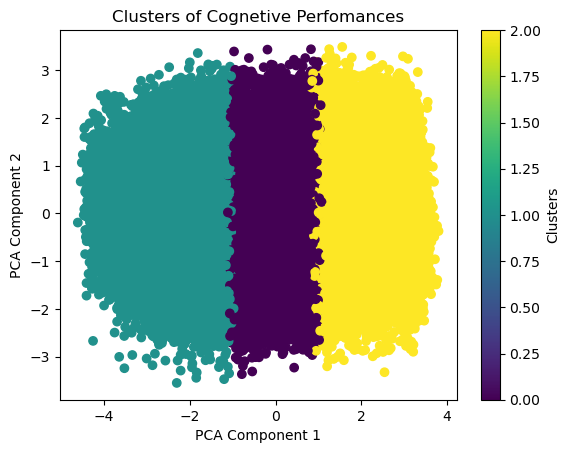

In [19]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap='viridis')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Clusters of Cognetive Perfomances')
plt.colorbar(label='Clusters')
plt.show()

### 3.4 Построим графики с центроидами

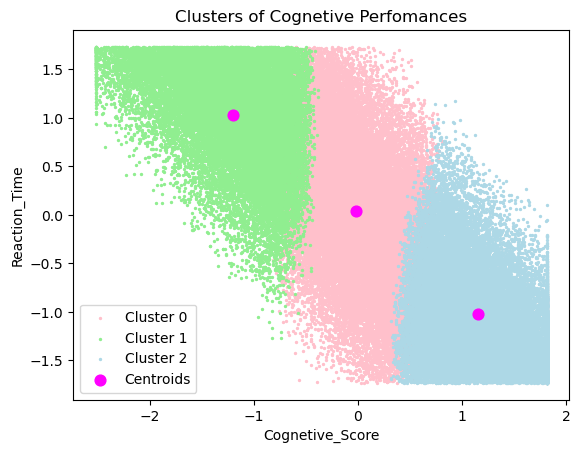

In [66]:
# данный график показывает, что когнетивные способности выше при меньшем времени реакции
plt.scatter(X[clusters == 0, 10], X[clusters == 0, 8], s = 2, c = 'pink', label = 'Cluster 0')
plt.scatter(X[clusters == 1, 10], X[clusters == 1, 8], s = 2, c = 'lightgreen', label = 'Cluster 1')
plt.scatter(X[clusters == 2, 10], X[clusters == 2, 8], s = 2, c = 'lightblue', label = 'Cluster 2')
plt.scatter(kmeans.cluster_centers_[:, 10], kmeans.cluster_centers_[0:, 8], s=60, c = 'magenta', label = 'Centroids')
plt.title('Clusters of Cognetive Perfomances')
plt.xlabel('Cognetive_Score')
plt.ylabel('Reaction_Time')
plt.legend()
plt.show()

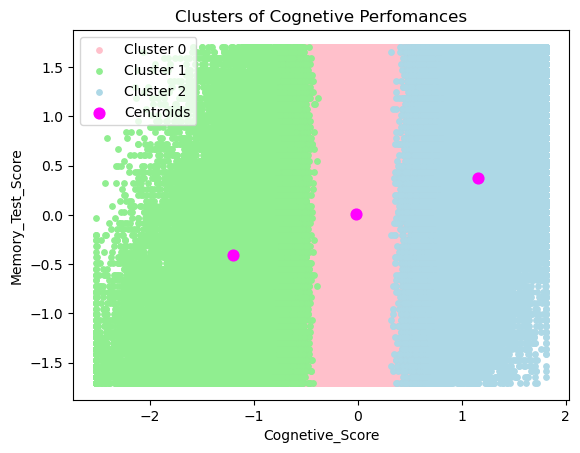

In [67]:
# данный график показывает, что когнетивные способности выше при лучшем состоянии памяти
plt.scatter(X[clusters == 0, 10], X[clusters == 0, 9], s = 15, c = 'pink', label = 'Cluster 0')
plt.scatter(X[clusters == 1, 10], X[clusters == 1, 9], s = 15, c = 'lightgreen', label = 'Cluster 1')
plt.scatter(X[clusters == 2, 10], X[clusters == 2, 9], s = 15, c = 'lightblue', label = 'Cluster 2')
plt.scatter(kmeans.cluster_centers_[:, 10], kmeans.cluster_centers_[0:, 9], s=60, c = 'magenta', label = 'Centroids')
plt.title('Clusters of Cognetive Perfomances')
plt.xlabel('Cognetive_Score')
plt.ylabel('Memory_Test_Score')
plt.legend()
plt.show()

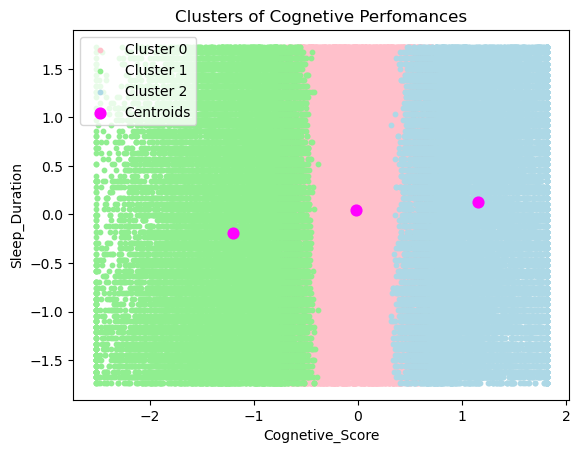

In [68]:
# данный график показывает, что когнетивные способности выше при большей продолжительности сна
plt.scatter(X[clusters == 0, 10], X[clusters == 0, 2], s = 10, c = 'pink', label = 'Cluster 0')
plt.scatter(X[clusters == 1, 10], X[clusters == 1, 2], s = 10, c = 'lightgreen', label = 'Cluster 1')
plt.scatter(X[clusters == 2, 10], X[clusters == 2, 2], s = 10, c = 'lightblue', label = 'Cluster 2')
plt.scatter(kmeans.cluster_centers_[:, 10], kmeans.cluster_centers_[0:, 2], s=60, c = 'magenta', label = 'Centroids')
plt.title('Clusters of Cognetive Perfomances')
plt.xlabel('Cognetive_Score')
plt.ylabel('Sleep_Duration')
plt.legend()
plt.show()

### 3.5 Исследуем результаты
Сгруппируем по кластерам и проанализируем средние значения в них:

In [14]:
dfLEnc['cluster'] = clusters
dfLEnc. groupby('cluster').mean()

,Age,Gender,Sleep_Duration,Stress_Level,Diet_Type,Daily_Screen_Time,Exercise_Frequency,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,AI_Predicted_Score
cluster,,,,,,,,,,,,
0,38.782183,0.556188,7.077413,5.479924,0.69071,6.483653,1.21454,249.206236,405.257707,69.679860,57.755175,57.765933
1,38.454321,0.566061,6.668818,6.194290,0.712353,7.197175,1.206757,268.493000,519.113577,62.398409,30.405482,30.287897
2,38.270493,0.561889,7.230428,4.854402,0.706051,5.881754,1.170489,230.430053,281.660552,75.926642,84.725646,84.659517


Как можно заметить, Кластер 1 имеет низкие когнетивные способности, кластер 0 - средние и кластер 2 превосходные. Анализируя можно сказать, что:
1) не влияют на результат: возраст и пол;
2) пропорционально повышают когнетивные способности: длительность сна и высокие результаты теста памяти;
3) обратно пропорционально влияют на когнетивные способности: уровень стресса, время проведённое за экраном, потребление кофеина, скорость реакции.

Для понимания влияния типа диеты и уровня физической подготовки сопоставим исходный и закодированный датасеты:

In [15]:
df[['Diet_Type', 'Exercise_Frequency']].head(6)

,Diet_Type,Exercise_Frequency
0,Non-Vegetarian,Medium
1,Non-Vegetarian,High
2,Vegetarian,Low
3,Vegetarian,Low
4,Non-Vegetarian,Medium
5,Vegan,Low


In [16]:
dfLEnc[['Diet_Type', 'Exercise_Frequency']].head(6)

,Diet_Type,Exercise_Frequency
0,0,2
1,0,0
2,2,1
3,2,1
4,0,2
5,1,1


Как можно заметить, не вегетрианская диета имеет значение 0, низкая физ подготовка имеет значение 1, высокая имеет значение 0. Смотрим на результаты выше и сопоставляем:
1) диета крайне слабо влияет, а лучшее значение у тех, кто её соблюдает;
2) чем выше уровень физ подготовки, тем выше когнетивные способности.
Важное примечание: для более детального исследования двух данных показателей лучше применить OneHotEncoder и посмотреть на корреляцию между ними и результатами (последние 2 колонки датасета)